In [37]:
# ============================================================
# 1. Imports and reproducibility
# ============================================================

!pip install -q scikit-learn pandas matplotlib openpyxl

import os
import json
import random
import zipfile
import datetime
import shutil

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
)

from sklearn.utils.class_weight import compute_class_weight

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow :", tf.__version__)
print("GPU :", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.21.0
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [38]:
# ============================================================
# 2. Clean extraction of the final dataset
# ============================================================

BASE_DIR = Path("/content")

ZIP_PATH = (
    BASE_DIR /
    "dataset_final_splits_v2.zip"
)

SPLIT_DATA_DIR = (
    BASE_DIR /
    "dataset_final_splits_v2"
)

if not ZIP_PATH.exists():
    raise FileNotFoundError(
        f"ZIP not found: {ZIP_PATH}"
    )

# Delete any previous extracted folder
# to avoid keeping outdated files
if SPLIT_DATA_DIR.exists():
    shutil.rmtree(SPLIT_DATA_DIR)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(BASE_DIR)

if not SPLIT_DATA_DIR.exists():
    raise FileNotFoundError(
        f"Extracted folder not found: {SPLIT_DATA_DIR}"
    )

print("Dataset cleanly extracted:", SPLIT_DATA_DIR)

Dataset cleanly extracted: /content/dataset_final_splits_v2


In [39]:
# ============================================================
# 3. Dataset Configuration
# ============================================================

PROJECT_NAME = (
    "MALLOULINOVA_dataset_workshop_redmi_apexel"
)

CLASS_NAMES_TARGET = [
    "original",
    "repeint"
]

NUM_CLASSES = len(CLASS_NAMES_TARGET)

IMG_SIZE = (384, 384)

BATCH_SIZE = 8

EPOCHS_PHASE1 = 10
EPOCHS_PHASE2 = 3

LR_PHASE1 = 1e-3
LR_PHASE2 = 1e-5
FINE_TUNE_LAST_N = 5

CONFIDENCE_THRESHOLD = 0.65

OUTPUT_DIR = (
    BASE_DIR /
    "outputs_training_workshop_v2"
)

for folder in [
    "weights",
    "metrics",
    "figures",
    "predictions",
]:
    (
        OUTPUT_DIR / folder
    ).mkdir(
        parents=True,
        exist_ok=True
    )

print("Classes:", CLASS_NAMES_TARGET)
print("Dataset:", SPLIT_DATA_DIR)
print("Outputs:", OUTPUT_DIR)

Classes: ['original', 'repeint']
Dataset: /content/dataset_final_splits_v2
Outputs: /content/outputs_training_workshop_v2


In [40]:
# ============================================================
# 4. Final dataset verification
# ============================================================

distribution_rows = []

for split in ["train", "val", "test"]:

    for label in CLASS_NAMES_TARGET:

        folder = (
            SPLIT_DATA_DIR /
            split /
            label
        )

        if not folder.exists():
            raise FileNotFoundError(
                f"Folder missing: {folder}"
            )

        count = len([
            path for path in folder.iterdir()
            if path.is_file()
        ])

        distribution_rows.append({
            "split": split,
            "label": label,
            "count": count,
        })

distribution_df = pd.DataFrame(
    distribution_rows
)

display(
    distribution_df.pivot(
        index="split",
        columns="label",
        values="count"
    )
)

print(
    "Total:",
    distribution_df["count"].sum()
)

label,original,repeint
split,,
test,22,29
train,112,54
val,23,24


Total: 264


In [41]:
# ============================================================
# TensorFlow Reset before a new training run
# ============================================================

tf.keras.backend.clear_session()

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [42]:
# ============================================================
# 5. Keras Data Loading
# ============================================================

AUTOTUNE = tf.data.AUTOTUNE

train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DATA_DIR / "train",
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES_TARGET,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)

val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DATA_DIR / "val",
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES_TARGET,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DATA_DIR / "test",
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES_TARGET,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

class_names = train_ds_raw.class_names

assert class_names == CLASS_NAMES_TARGET, (
    f"Unexpected classes: {class_names}"
)

train_file_paths = list(
    train_ds_raw.file_paths
)

val_file_paths = list(
    val_ds_raw.file_paths
)

test_file_paths = list(
    test_ds_raw.file_paths
)

train_ds = train_ds_raw.prefetch(AUTOTUNE)
val_ds = val_ds_raw.prefetch(AUTOTUNE)
test_ds = test_ds_raw.prefetch(AUTOTUNE)

print("Classes:", class_names)
print("Train:", len(train_file_paths))
print("Val:", len(val_file_paths))
print("Test:", len(test_file_paths))

Found 166 files belonging to 2 classes.
Found 47 files belonging to 2 classes.
Found 51 files belonging to 2 classes.
Classes: ['original', 'repeint']
Train: 166
Val: 47
Test: 51


In [43]:
# ============================================================
# 6. Class weights
# ============================================================

train_counts = []

for label in CLASS_NAMES_TARGET:

    folder = (
        SPLIT_DATA_DIR /
        "train" /
        label
    )

    count = len([
        path for path in folder.iterdir()
        if path.is_file()
    ])

    train_counts.append(count)

train_labels = []

for class_index, count in enumerate(train_counts):
    train_labels.extend(
        [class_index] * count
    )

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=np.array(train_labels)
)

class_weight = {
    index: float(weight)
    for index, weight in enumerate(weights)
}

print("Train distribution:", dict(
    zip(CLASS_NAMES_TARGET, train_counts)
))

print("Class weights:", class_weight)

Train distribution: {'original': 112, 'repeint': 54}
Class weights: {0: 0.7410714285714286, 1: 1.537037037037037}


In [44]:
# ============================================================
# 7. Data augmentation
# ============================================================
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip(
            "horizontal",
            seed=SEED
        ),

        layers.RandomRotation(
            0.03,
            seed=SEED
        ),

        layers.RandomTranslation(
            height_factor=0.03,
            width_factor=0.03,
            seed=SEED
        ),

        layers.RandomZoom(
            height_factor=0.05,
            width_factor=0.05,
            seed=SEED
        ),

        layers.RandomContrast(
            0.08,
            seed=SEED
        ),

        layers.RandomBrightness(
            0.05,
            seed=SEED
        ),
    ],
    name="data_augmentation"
)

In [45]:
# ============================================================
# 8. Building the binary EfficientNet-B0 model
# ============================================================

TOP = 32
BOTTOM = 32
LEFT = 32
RIGHT = 32

def build_efficientnetb0_binary_model(
    img_size=(384, 384),
    num_classes=2,
    dense_units=128,
    dropout_1=0.5,
    dropout_2=0.3,
    l2_reg=1e-3,
):
    inputs = keras.Input(shape=img_size + (3,), name="input_image")

    # Augmentation active only during training=True

    x = layers.Cropping2D(cropping=((TOP, BOTTOM), (LEFT, RIGHT)), name="useful_crop_zone")(inputs)
    x = layers.Resizing(height=384, width=384, name="resize_after_crop")(x)

    x = data_augmentation(x)

    # Official EfficientNet API; in some versions, this function is a no-op
    # because EfficientNet already integrates normalization. Keeping it guarantees compatibility.
    x = tf.keras.applications.efficientnet.preprocess_input(x)

    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=img_size + (3,),
    )
    base_model.trainable = False

    # training=False keeps BatchNorm in inference mode, stable for small dataset.
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dropout(dropout_1, name="dropout_head_1")(x)
    x = layers.Dense(
        dense_units,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(l2_reg),
        name="dense_texture_head",
    )(x)
    x = layers.Dropout(dropout_2, name="dropout_head_2")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="classification_softmax")(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name="efficientnetb0_binary_malloulinova")
    return model, base_model


model, base_model = build_efficientnetb0_binary_model(
    img_size=IMG_SIZE,
    num_classes=NUM_CLASSES,
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR_PHASE1),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()
print("Backbone:", base_model.name)
print("Backbone trainable:", base_model.trainable)

Model: "efficientnetb0_binary_malloulinova"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ useful_crop_zone (Cropping2D)   │ (None, 320, 320, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resize_after_crop (Resizing)    │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 12, 12, 1280)   │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_head_1 (Dropout)        │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_texture_head (Dense)      │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_head_2 (Dropout)        │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_softmax (Dense)  │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,797 (16.07 MB)

 Trainable params: 164,226 (641.51 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Backbone: efficientnetb0
Backbone trainable: False


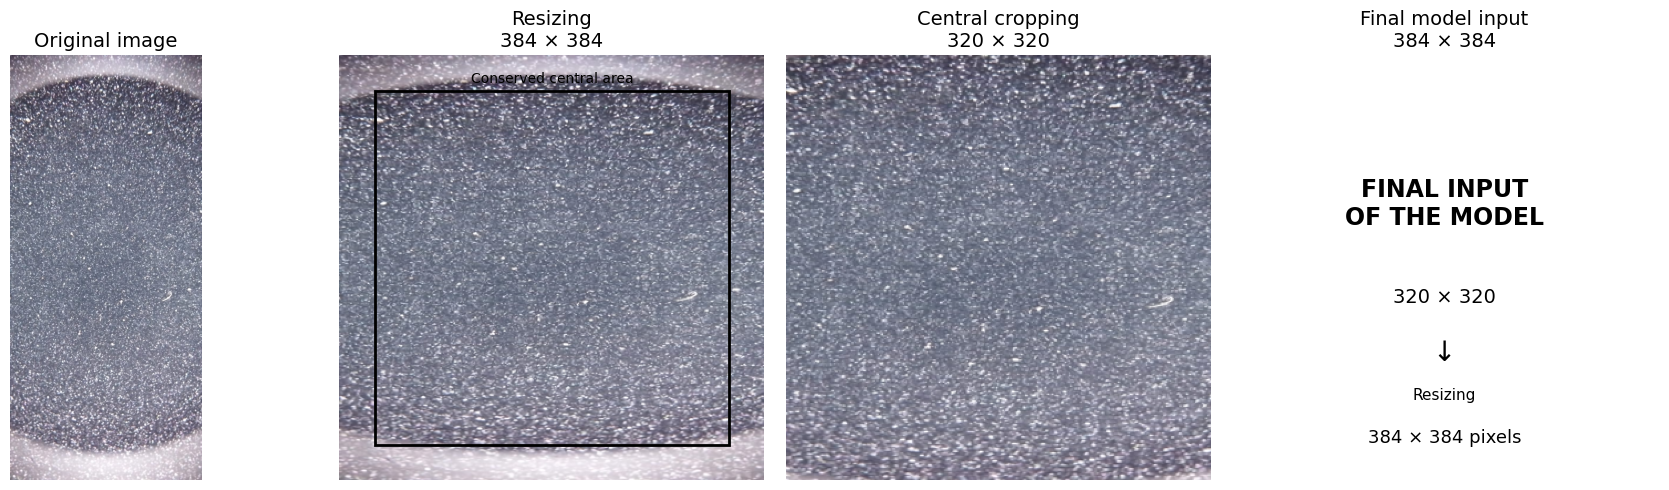

Figure saved: /content/outputs_training_workshop_v2/figures/figure_3_3_image_preparation.png


In [46]:
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from pathlib import Path

# ============================================================
# FIGURE 3.3 — PREPARING AN IMAGE BEFORE INFERENCE
# ============================================================

# Selection of an image from the test set
image_path = test_file_paths[0]

# Loading the original image
image_original = Image.open(image_path).convert("RGB")

# ------------------------------------------------------------
# 1. Resize to 384 × 384
# ------------------------------------------------------------
image_384 = image_original.resize(IMG_SIZE)

# ------------------------------------------------------------
# 2. Central cropping: 32 pixels on each side
# ------------------------------------------------------------
image_cropped = image_384.crop(
    (
        LEFT,
        TOP,
        IMG_SIZE[1] - RIGHT,
        IMG_SIZE[0] - BOTTOM
    )
)

# image_cropped = 320 × 320

# ------------------------------------------------------------
# Creating the figure
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# ============================================================
# STEP 1 — ORIGINAL IMAGE
# ============================================================
axes[0].imshow(image_original)
axes[0].set_title("Original image", fontsize=14)
axes[0].axis("off")


# ============================================================
# STEP 2 — RESIZING 384 × 384
# ============================================================
axes[1].imshow(image_384)
axes[1].set_title("Resizing\n384 × 384", fontsize=14)
axes[1].axis("off")

# Rectangle indicating the conserved central area
rect = Rectangle(
    (LEFT, TOP),
    IMG_SIZE[1] - LEFT - RIGHT,
    IMG_SIZE[0] - TOP - BOTTOM,
    fill=False,
    linewidth=2
)

axes[1].add_patch(rect)

# Annotation of the conserved area
axes[1].text(
    IMG_SIZE[1] / 2,
    TOP - 5,
    "Conserved central area",
    ha="center",
    va="bottom",
    fontsize=10
)


# ============================================================
# STEP 3 — CENTRAL CROPPING 320 × 320
# ============================================================
axes[2].imshow(image_cropped)
axes[2].set_title("Central cropping\n320 × 320", fontsize=14)
axes[2].axis("off")


# ============================================================
# STEP 4 — FINAL INPUT OF THE MODEL
# ============================================================
axes[3].axis("off")

axes[3].text(
    0.5,
    0.65,
    "FINAL INPUT\nOF THE MODEL",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold",
    transform=axes[3].transAxes
)

axes[3].text(
    0.5,
    0.43,
    "320 × 320",
    ha="center",
    va="center",
    fontsize=14,
    transform=axes[3].transAxes
)

axes[3].text(
    0.5,
    0.30,
    "↓",
    ha="center",
    va="center",
    fontsize=20,
    transform=axes[3].transAxes
)

axes[3].text(
    0.5,
    0.20,
    "Resizing",
    ha="center",
    va="center",
    fontsize=11,
    transform=axes[3].transAxes
)

axes[3].text(
    0.5,
    0.10,
    "384 × 384 pixels",
    ha="center",
    va="center",
    fontsize=13,
    transform=axes[3].transAxes
)

axes[3].set_title(
    "Final model input\n384 × 384",
    fontsize=14
)


# ============================================================
# LAYOUT
# ============================================================
plt.tight_layout()

# Creating the figures folder
figures_dir = Path(OUTPUT_DIR) / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Saving in high resolution
output_path = figures_dir / "figure_3_3_image_preparation.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved: {output_path}")

In [47]:
# ============================================================
# 9. Phase 1 Callbacks
# ============================================================

checkpoint_phase1 = OUTPUT_DIR / "weights" / "efficientnet_binary_phase1_best.keras"

callbacks_phase1 = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_phase1),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.2,
        patience=1,
        min_lr=1e-6,
        verbose=1
    )
]

print("Checkpoint Phase 1:", checkpoint_phase1)

Checkpoint Phase 1: /content/outputs_training_workshop_v2/weights/efficientnet_binary_phase1_best.keras


In [48]:
# ============================================================
# 10. Phase 1 Training: Frozen Backbone
# ============================================================

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE1,
    callbacks=callbacks_phase1,
    class_weight=class_weight,
)

Epoch 1/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.5960 - loss: 0.8827
Epoch 1: val_loss improved from None to 0.96816, saving model to /content/outputs_training_workshop_v2/weights/efficientnet_binary_phase1_best.keras

Epoch 1: finished saving model to /content/outputs_training_workshop_v2/weights/efficientnet_binary_phase1_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 24s 319ms/step - accuracy: 0.5783 - loss: 0.8718 - val_accuracy: 0.5957 - val_loss: 0.9682 - learning_rate: 0.0010
Epoch 2/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.6774 - loss: 0.7999
Epoch 2: val_loss improved from 0.96816 to 0.83635, saving model to /content/outputs_training_workshop_v2/weights/efficientnet_binary_phase1_best.keras

Epoch 2: finished saving model to /content/outputs_training_workshop_v2/weights/efficientnet_binary_phase1_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 177ms/step - accuracy: 0.7289 - loss: 0.7777 - val_accuracy: 0.6170 - val_loss: 0.8363 - learning_rate: 0.0010
Epoch 

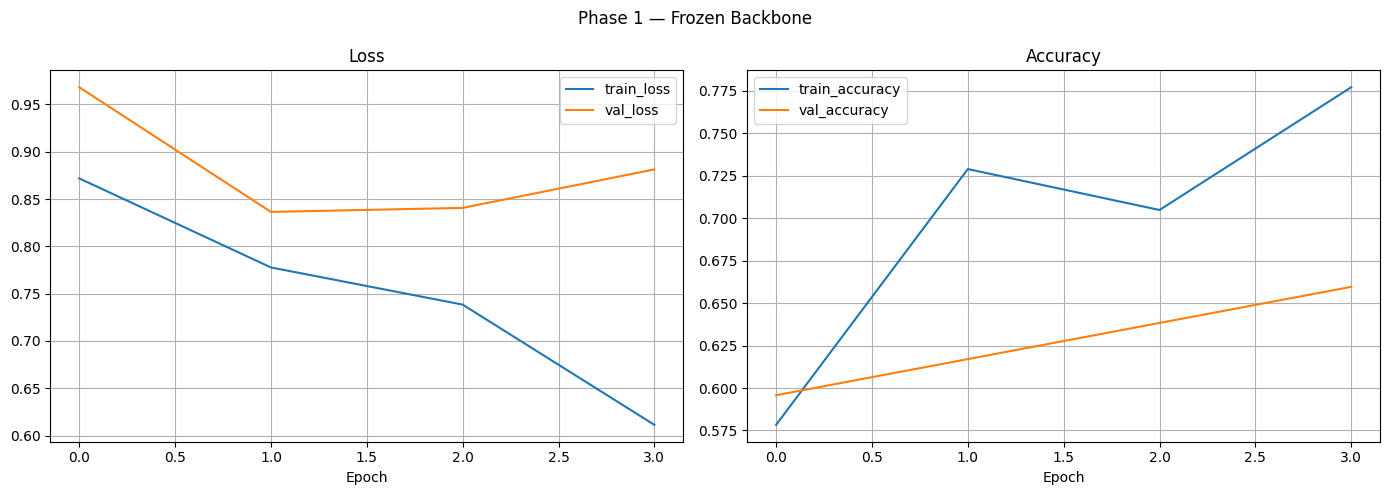

In [49]:
# ============================================================
# 11. Phase 1 Curves
# ============================================================


def plot_history(history, title="Training History"):
    hist = history.history
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(hist.get("loss", []), label="train_loss")
    axes[0].plot(hist.get("val_loss", []), label="val_loss")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(hist.get("accuracy", []), label="train_accuracy")
    axes[1].plot(hist.get("val_accuracy", []), label="val_accuracy")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    axes[1].grid(True)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_history(history1, "Phase 1 — Frozen Backbone")

In [50]:
# ============================================================
# 12. Fine-tuning Phase 2
# ============================================================

# Load the best Phase 1 checkpoint
model.load_weights(
    str(checkpoint_phase1)
)

print("Best Phase 1 checkpoint reloaded.")

base_model.trainable = True

# Freeze all layers except the last N
for layer in base_model.layers[:-FINE_TUNE_LAST_N]:
    layer.trainable = False

# Keep all BatchNorm layers frozen, even in unfrozen layers
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

n_trainable = sum(1 for layer in base_model.layers if layer.trainable)
n_total = len(base_model.layers)
print(f"Trainable backbone layers: {n_trainable}/{n_total}")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR_PHASE2),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

checkpoint_phase2 = OUTPUT_DIR / "weights" / "efficientnet_binary_phase2_best.keras"

callbacks_phase2 = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_phase2),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.2,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )
]
initial_epoch = len(history1.history.get("loss", []))
total_epochs = initial_epoch + EPOCHS_PHASE2

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=total_epochs,
    initial_epoch=initial_epoch,
    callbacks=callbacks_phase2,
    class_weight=class_weight,
)

Best Phase 1 checkpoint reloaded.
Trainable backbone layers: 3/238
Epoch 5/7
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.6966 - loss: 0.6885
Epoch 5: val_loss improved from None to 0.89376, saving model to /content/outputs_training_workshop_v2/weights/efficientnet_binary_phase2_best.keras

Epoch 5: finished saving model to /content/outputs_training_workshop_v2/weights/efficientnet_binary_phase2_best.keras
21/21 ━━━━━━━━━━━━━━━━━━━━ 18s 333ms/step - accuracy: 0.6988 - loss: 0.7014 - val_accuracy: 0.6383 - val_loss: 0.8938 - learning_rate: 1.0000e-05
Epoch 6/7
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.7284 - loss: 0.7012
Epoch 6: val_loss did not improve from 0.89376

Epoch 6: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 167ms/step - accuracy: 0.7048 - loss: 0.7029 - val_accuracy: 0.6383 - val_loss: 0.9398 - learning_rate: 1.0000e-05
Epoch 7/7
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.7743 - loss: 0

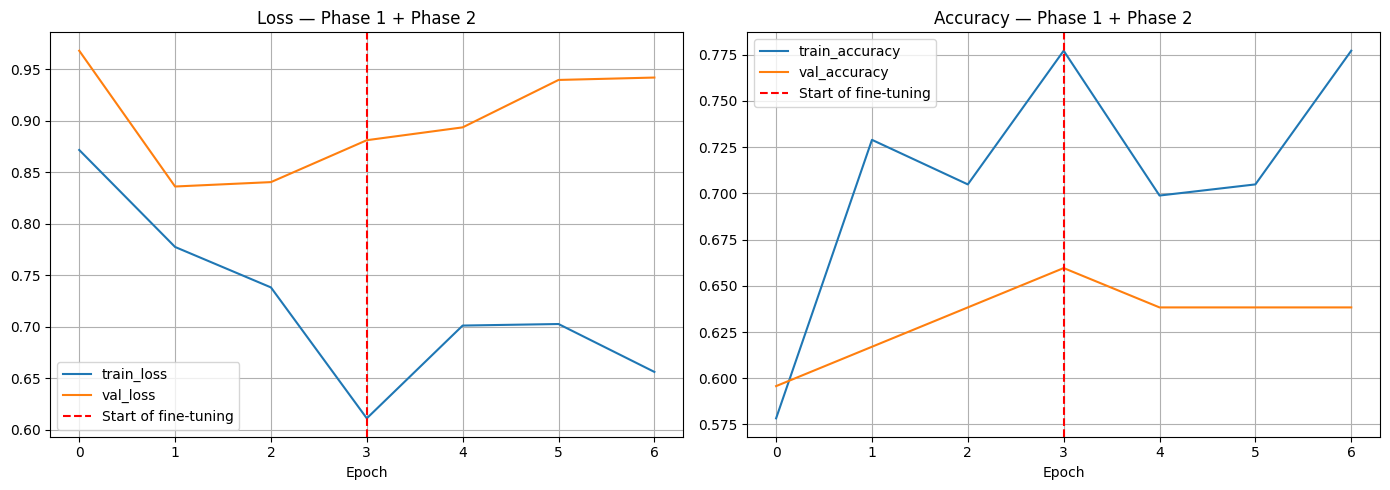

Curves saved: /content/outputs_training_workshop_v2/figures/training_curves_phase1_phase2.png


In [51]:
# ============================================================
# 13. Combined Phase 1 + Phase 2 Curves
# ============================================================


def combine_histories(*histories):
    combined = {}
    for history in histories:
        for key, values in history.history.items():
            combined.setdefault(key, []).extend(values)
    return combined


combined_history = combine_histories(history1, history2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(combined_history.get("loss", []), label="train_loss")
axes[0].plot(combined_history.get("val_loss", []), label="val_loss")
axes[0].axvline(initial_epoch - 1, color="red", linestyle="--", label="Start of fine-tuning")
axes[0].set_title("Loss — Phase 1 + Phase 2")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(combined_history.get("accuracy", []), label="train_accuracy")
axes[1].plot(combined_history.get("val_accuracy", []), label="val_accuracy")
axes[1].axvline(initial_epoch - 1, color="red", linestyle="--", label="Start of fine-tuning")
axes[1].set_title("Accuracy — Phase 1 + Phase 2")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
history_fig_path = OUTPUT_DIR / "figures" / "training_curves_phase1_phase2.png"
plt.savefig(history_fig_path, dpi=150, bbox_inches="tight")
plt.show()

with open(OUTPUT_DIR / "metrics" / "training_history.json", "w", encoding="utf-8") as f:
    json.dump({k: [float(x) for x in v] for k, v in combined_history.items()}, f, indent=2)

print("Curves saved:", history_fig_path)

In [52]:
# ============================================================
# 14. Selected Model
# ============================================================

chosen_model = model
chosen_model_name = "Phase 2"

POSITIVE_LABEL = "repeint"
POSITIVE_INDEX = 1

print("Model used:", chosen_model_name)
print("Positive class:", POSITIVE_LABEL)

Model used: Phase 2
Positive class: repeint


In [53]:
# ============================================================
# 15. Prediction function
# ============================================================

def collect_predictions(dataset, model):

    y_true_batches = []

    for _, labels in dataset:
        y_true_batches.append(
            np.argmax(
                labels.numpy(),
                axis=1
            )
        )

    y_true = np.concatenate(
        y_true_batches,
        axis=0
    )

    y_prob = model.predict(
        dataset,
        verbose=1
    )

    y_pred = np.argmax(
        y_prob,
        axis=1
    )

    return y_true, y_prob, y_pred

In [54]:
# ============================================================
# 16. Raw evaluation on Test
# ============================================================

y_true_test, y_prob_test, y_pred_test = (
    collect_predictions(
        test_ds,
        chosen_model
    )
)

test_loss, test_accuracy_keras = (
    chosen_model.evaluate(
        test_ds,
        verbose=0
    )
)

accuracy_test = accuracy_score(
    y_true_test,
    y_pred_test
)

balanced_accuracy_test = balanced_accuracy_score(
    y_true_test,
    y_pred_test
)

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_true_test,
        y_pred_test,
        labels=[0, 1],
        zero_division=0
    )
)

f1_macro_test = f1.mean()

print("Test loss:", round(float(test_loss), 4))
print("Accuracy:", round(float(accuracy_test), 4))
print(
    "Balanced accuracy:",
    round(float(balanced_accuracy_test), 4)
)
print(
    "F1 macro:",
    round(float(f1_macro_test), 4)
)
print(
    "Recall Repeint:",
    round(float(recall[1]), 4)
)
print(
    "F1 Repeint:",
    round(float(f1[1]), 4)
)

print(
    classification_report(
        y_true_test,
        y_pred_test,
        labels=[0, 1],
        target_names=class_names,
        zero_division=0
    )
)

7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 398ms/step
Test loss: 0.8098
Accuracy: 0.6863
Balanced accuracy: 0.7132
F1 macro: 0.6832
Recall Repeint: 0.5172
F1 Repeint: 0.6522
              precision    recall  f1-score   support

    original       0.59      0.91      0.71        22
     repeint       0.88      0.52      0.65        29

    accuracy                           0.69        51
   macro avg       0.74      0.71      0.68        51
weighted avg       0.76      0.69      0.68        51



In [55]:
y_true_val, y_prob_val, _ = (
    collect_predictions(
        val_ds,
        chosen_model
    )
)

threshold_rows = []

for threshold in np.arange(
    0.20,
    0.61,
    0.01
):

    y_pred_val_threshold = (
        y_prob_val[:, POSITIVE_INDEX]
        >= threshold
    ).astype(int)

    precision_val, recall_val, f1_val, _ = (
        precision_recall_fscore_support(
            y_true_val,
            y_pred_val_threshold,
            labels=[0, 1],
            zero_division=0
        )
    )

    threshold_rows.append({
        "threshold_repeint": round(
            float(threshold),
            2
        ),
        "precision_repeint": precision_val[1],
        "recall_repeint": recall_val[1],
        "f1_repeint": f1_val[1],
        "f1_macro": f1_val.mean(),
        "balanced_accuracy": balanced_accuracy_score(
            y_true_val,
            y_pred_val_threshold
        )
    })

threshold_df = pd.DataFrame(
    threshold_rows
)

display(
    threshold_df.sort_values(
        "f1_macro",
        ascending=False
    ).head(10)
)

best_row = threshold_df.loc[
    threshold_df["f1_macro"].idxmax()
]

BEST_REPEINT_THRESHOLD = float(
    best_row["threshold_repeint"]
)

print(
    "Selected Repeint threshold:",
    BEST_REPEINT_THRESHOLD
)

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step


,threshold_repeint,precision_repeint,recall_repeint,f1_repeint,f1_macro,balanced_accuracy
37,0.57,0.681818,0.625000,0.652174,0.659420,0.660326
36,0.56,0.681818,0.625000,0.652174,0.659420,0.660326
33,0.53,0.681818,0.625000,0.652174,0.659420,0.660326
32,0.52,0.681818,0.625000,0.652174,0.659420,0.660326
35,0.55,0.681818,0.625000,0.652174,0.659420,0.660326
34,0.54,0.681818,0.625000,0.652174,0.659420,0.660326
40,0.60,0.700000,0.583333,0.636364,0.658182,0.661232
24,0.44,0.652174,0.625000,0.638298,0.638298,0.638587
25,0.45,0.652174,0.625000,0.638298,0.638298,0.638587
27,0.47,0.652174,0.625000,0.638298,0.638298,0.638587


Selected Repeint threshold: 0.52


In [56]:
# ============================================================
# 18. Uncertainty Threshold and final verdict
# ============================================================

proba_repeint_test = (
    y_prob_test[:, POSITIVE_INDEX]
)

confidence_test = np.max(
    y_prob_test,
    axis=1
)

raw_prediction_test = (
    proba_repeint_test
    >= BEST_REPEINT_THRESHOLD
).astype(int)

accepted_test = (
    confidence_test
    >= CONFIDENCE_THRESHOLD
)

verdict_final_test = []

for i in range(len(y_prob_test)):

    if not accepted_test[i]:
        verdict_final_test.append("uncertain")

    elif raw_prediction_test[i] == 1:
        verdict_final_test.append("repeint")

    else:
        verdict_final_test.append("original")

print("Total count:", len(verdict_final_test))
print(
    "Accepted images:",
    int(accepted_test.sum())
)
print(
    "Uncertain images:",
    int((~accepted_test).sum())
)
print(
    "Uncertain rate:",
    round(
        float((~accepted_test).mean()),
        4
    )
)
print(
    "Coverage:",
    round(
        float(accepted_test.mean()),
        4
    )
)

Total count: 51
Accepted images: 36
Uncertain images: 15
Uncertain rate: 0.2941
Coverage: 0.7059


In [57]:
# ============================================================
# 19. Exporting the results
# ============================================================

final_results_df = pd.DataFrame({
    "file_path": test_file_paths,
    "true_class": [
        class_names[i]
        for i in y_true_test
    ],
    "proba_original": y_prob_test[:, 0],
    "proba_repeint": y_prob_test[:, 1],
    "raw_prediction": [
        class_names[i]
        for i in raw_prediction_test
    ],
    "confidence": confidence_test,
    "repaint_threshold": BEST_REPEINT_THRESHOLD,
    "confidence_threshold": CONFIDENCE_THRESHOLD,
    "verdict_final": verdict_final_test,
    "accepted": accepted_test,
})

final_results_path = (
    OUTPUT_DIR /
    "predictions" /
    "final_predictions_workshop.csv"
)

final_results_df.to_csv(
    final_results_path,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Results saved:",
    final_results_path
)

Results saved: /content/outputs_training_workshop_v2/predictions/final_predictions_workshop.csv


Binary AUC for positive class 'repeint': 0.6755


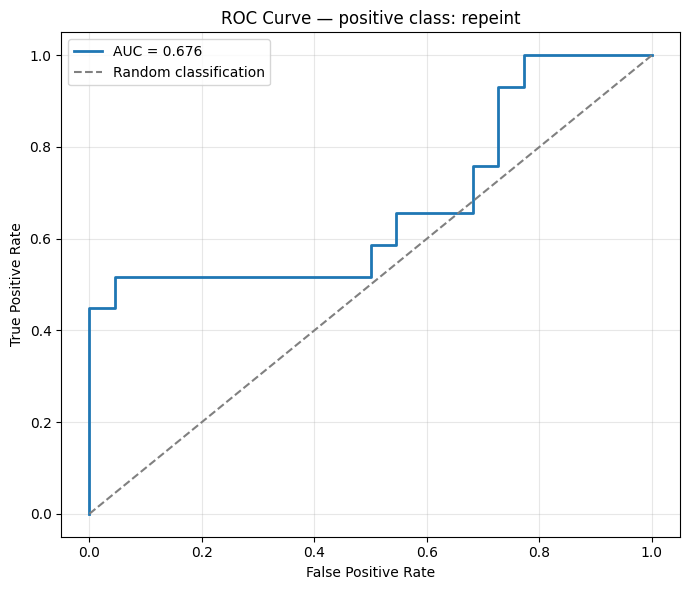

In [58]:
# ============================================================
# 20. AUC and ROC curve
# ============================================================

try:
    auc_value = roc_auc_score(
        y_true_test,
        y_prob_test[:, POSITIVE_INDEX]
    )

    fpr, tpr, roc_thresholds = roc_curve(
        y_true_test,
        y_prob_test[:, POSITIVE_INDEX],
        pos_label=POSITIVE_INDEX
    )

    print(
        f"Binary AUC for positive class "
        f"'{POSITIVE_LABEL}': {auc_value:.4f}"
    )

    plt.figure(figsize=(7, 6))

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"AUC = {auc_value:.3f}"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray",
        label="Random classification"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(
        f"ROC Curve — positive class: {POSITIVE_LABEL}"
    )

    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    roc_path = (
        OUTPUT_DIR /
        "figures" /
        "roc_curve_test_workshop.png"
    )

    plt.savefig(
        roc_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

except ValueError as error:
    auc_value = None
    print("AUC could not be calculated:", error)

Confusion matrix:
[[20  2]
 [14 15]]


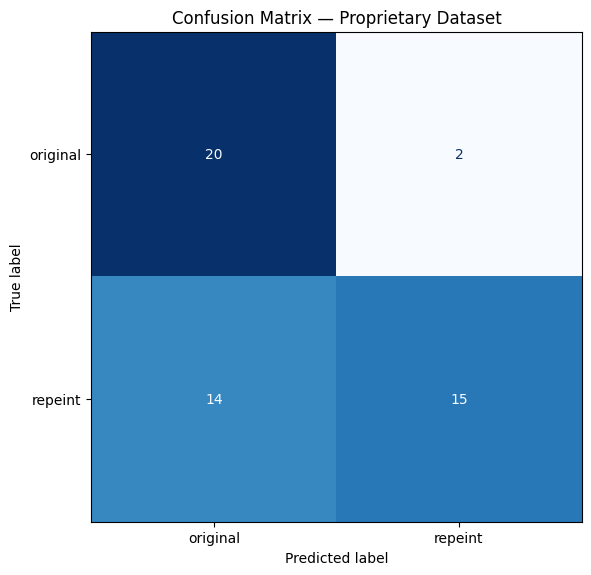

Matrix saved: /content/outputs_training_workshop_v2/figures/confusion_matrix_test_workshop.png


In [59]:
# ============================================================
# 21. Confusion Matrix
# ============================================================

cm = confusion_matrix(
    y_true_test,
    y_pred_test,
    labels=[0, 1]
)

print("Confusion matrix:")
print(cm)

fig, ax = plt.subplots(
    figsize=(6, 6)
)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display_cm.plot(
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=ax
)

ax.set_title(
    "Confusion Matrix — Proprietary Dataset"
)

plt.tight_layout()

cm_path = (
    OUTPUT_DIR /
    "figures" /
    "confusion_matrix_test_workshop.png"
)

plt.savefig(
    cm_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Matrix saved:", cm_path)

In [60]:
# ============================================================
# 22. Error Analysis
# ============================================================

index_to_class = {
    index: label
    for index, label in enumerate(class_names)
}


error_indices = np.where(
    y_true_test != y_pred_test
)[0]

print("=" * 60)
print(
    f"ERRORS: {len(error_indices)} "
    f"out of {len(y_true_test)} images"
)
print("=" * 60)

error_rows = []

for index in error_indices:

    error_rows.append({
        "file_path": test_file_paths[index],
        "filename": os.path.basename(
            test_file_paths[index]
        ),
        "true_class": index_to_class[
            int(y_true_test[index])
        ],
        "predicted_class": index_to_class[
            int(y_pred_test[index])
        ],
        "confidence": float(
            confidence_test[index]
        ),
        "confidence_percent": float(
            confidence_test[index] * 100
        ),
        "proba_original": float(
            y_prob_test[index, 0]
        ),
        "proba_repeint": float(
            y_prob_test[index, 1]
        ),
    })

error_df = pd.DataFrame(error_rows)

if len(error_df) > 0:
    display(error_df)
else:
    print("No errors.")

error_path = (
    OUTPUT_DIR /
    "predictions" /
    "test_errors_workshop.csv"
)

error_df.to_csv(
    error_path,
    index=False,
    encoding="utf-8-sig"
)

print("Errors saved:", error_path)

ERRORS: 16 out of 51 images


,file_path,filename,true_class,predicted_class,confidence,confidence_percent,proba_original,proba_repeint
0,/content/dataset_final_splits_v2/test/original...,image_186.jpeg,original,repeint,0.609765,60.976540,0.390235,0.609765
1,/content/dataset_final_splits_v2/test/original...,image_188.jpeg,original,repeint,0.517492,51.749222,0.482508,0.517492
2,/content/dataset_final_splits_v2/test/repeint/...,image_015.jpeg,repeint,original,0.660732,66.073174,0.660732,0.339268
3,/content/dataset_final_splits_v2/test/repeint/...,image_016.jpeg,repeint,original,0.692051,69.205132,0.692051,0.307949
4,/content/dataset_final_splits_v2/test/repeint/...,image_017.jpeg,repeint,original,0.648381,64.838112,0.648381,0.351619
5,/content/dataset_final_splits_v2/test/repeint/...,image_018.jpeg,repeint,original,0.714001,71.400070,0.714001,0.285999
6,/content/dataset_final_splits_v2/test/repeint/...,image_019.jpeg,repeint,original,0.718638,71.863846,0.718638,0.281362
7,/content/dataset_final_splits_v2/test/repeint/...,image_020.jpeg,repeint,original,0.713393,71.339325,0.713393,0.286607
8,/content/dataset_final_splits_v2/test/repeint/...,image_239.jpeg,repeint,original,0.714001,71.400070,0.714001,0.285999
9,/content/dataset_final_splits_v2/test/repeint/...,image_240.jpeg,repeint,original,0.660732,66.073174,0.660732,0.339268


Errors saved: /content/outputs_training_workshop_v2/predictions/test_errors_workshop.csv


In [61]:
# ============================================================
# 23. JSON Summary
# ============================================================

metrics_summary = {
    "dataset_source": "MALLOULIAUTO_dataset_workshop",
    "dataset_type": "proprietary_pilot",
    "smartphone": "Redmi Note 12",
    "module": "Apexel",
    "input_size": list(IMG_SIZE),
    "classes": class_names,
    "positive_class_for_auc": POSITIVE_LABEL,
    "n_test_images": int(len(y_true_test)),
    "test_loss": float(test_loss),
    "test_accuracy_keras": float(
        test_accuracy_keras
    ),
    "accuracy_sklearn": float(
        accuracy_test
    ),
    "balanced_accuracy": float(
        balanced_accuracy_test
    ),
    "precision_macro": float(
        precision.mean()
    ),
    "recall_macro": float(
        recall.mean()
    ),
    "f1_macro": float(
        f1_macro_test
    ),
    "precision_original": float(
        precision[0]
    ),
    "recall_original": float(
        recall[0]
    ),
    "f1_original": float(
        f1[0]
    ),
    "precision_repeint": float(
        precision[1]
    ),
    "recall_repeint": float(
        recall[1]
    ),
    "f1_repeint": float(
        f1[1]
    ),
    "auc_repeint": (
        float(auc_value)
        if auc_value is not None
        else None
    ),
    "n_errors": int(len(error_indices)),
    "error_rate": float(
        len(error_indices) / len(y_true_test)
    ),
    "timestamp": datetime.datetime.now().isoformat(),
}

summary_path = (
    OUTPUT_DIR /
    "metrics" /
    "metrics_summary_test_workshop.json"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        metrics_summary,
        file,
        indent=2,
        ensure_ascii=False
    )

print(
    json.dumps(
        metrics_summary,
        indent=2,
        ensure_ascii=False
    )
)

print(
    "Summary saved:",
    summary_path
)

{
  "dataset_source": "MALLOULIAUTO_dataset_workshop",
  "dataset_type": "proprietary_pilot",
  "smartphone": "Redmi Note 12",
  "module": "Apexel",
  "input_size": [
    384,
    384
  ],
  "classes": [
    "original",
    "repeint"
  ],
  "positive_class_for_auc": "repeint",
  "n_test_images": 51,
  "test_loss": 0.8098499178886414,
  "test_accuracy_keras": 0.686274528503418,
  "accuracy_sklearn": 0.6862745098039216,
  "balanced_accuracy": 0.713166144200627,
  "precision_macro": 0.7352941176470589,
  "recall_macro": 0.713166144200627,
  "f1_macro": 0.6832298136645962,
  "precision_original": 0.5882352941176471,
  "recall_original": 0.9090909090909091,
  "f1_original": 0.7142857142857143,
  "precision_repeint": 0.8823529411764706,
  "recall_repeint": 0.5172413793103449,
  "f1_repeint": 0.6521739130434783,
  "auc_repeint": 0.6755485893416928,
  "n_errors": 16,
  "error_rate": 0.3137254901960784,
  "timestamp": "2026-11-01T11:44:04.918079"
}
Summary saved: /content/outputs_training_works